<a href="https://colab.research.google.com/github/ayeshmm3/Self-Learning-Tutorial/blob/main/Breast_Cancer_ML_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install pandas numpy matplotlib scikit-learn

  Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl (9.6 MB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.2 MB 11.3 MB/s eta 0:00:01
   ---------------- ----------------------- 3.4/8.2 MB 12.9 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.2 MB 12.4 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 11.4 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   -----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load the public Breast Cancer Wisconsin dataset
cancer = load_breast_cancer()

# Convert measurements into a DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Create a binary target: 1 = malignant, 0 = benign
df["malignant"] = (cancer.target == 0).astype(int)

print("Dataset shape:", df.shape)
print("\nDiagnosis counts:")
print(df["malignant"].value_counts().rename(
    index={0: "Benign", 1: "Malignant"}
))

print("\nMissing values:", df.isna().sum().sum())

Dataset shape: (569, 31)

Diagnosis counts:
malignant
Benign       357
Malignant    212
Name: count, dtype: int64

Missing values: 0


## Dataset Overview

The Breast Cancer Wisconsin Diagnostic dataset contains 569 samples with 30 numerical features describing cell characteristics.

Of the 569 samples, 357 are classified as benign and 212 as malignant. There are no missing values in the dataset.

The goal of this project is to compare Logistic Regression and Random Forest models to determine how well they classify tumors using these measurements.

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1



Summary statistics:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08,0.37
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02,0.48
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06,0.00
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07,0.00
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08,0.00
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09,1.00
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21,1.00


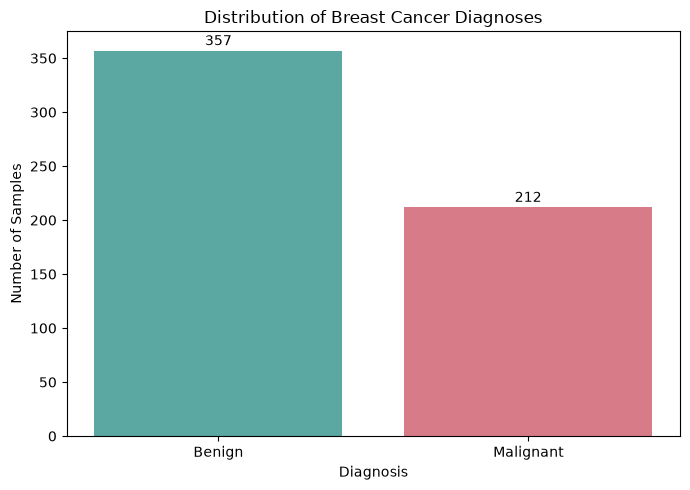

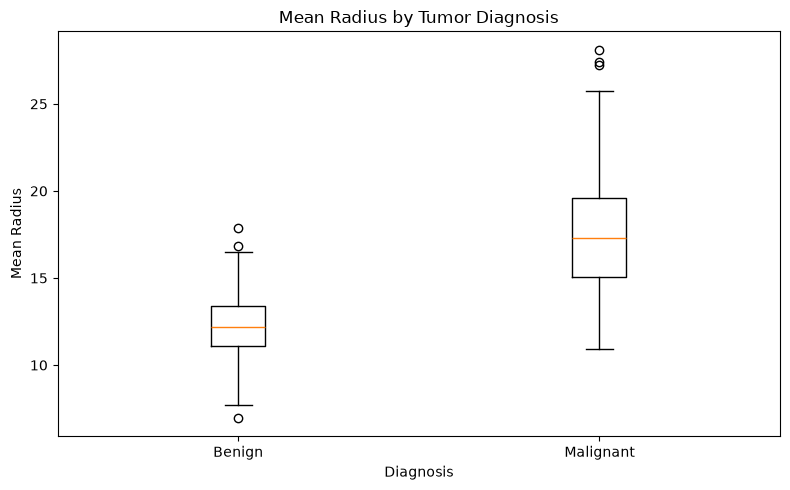

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# 1. SHOW THE FIRST FIVE RECORDS
# ==========================================

print("First five records:")
display(df.head())


# ==========================================
# 2. SUMMARY STATISTICS
# ==========================================

print("\nSummary statistics:")
display(df.describe().round(2))


# ==========================================
# 3. VISUALIZE DIAGNOSIS DISTRIBUTION
# ==========================================

diagnosis_counts = df["malignant"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Benign", "Malignant"],
    diagnosis_counts.values,
    color=["#5BA7A1", "#D77B88"]
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


# ==========================================
# 4. COMPARE MEAN RADIUS BY DIAGNOSIS
# ==========================================

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df["malignant"] == 0, "mean radius"],
        df.loc[df["malignant"] == 1, "mean radius"]
    ],
    tick_labels=["Benign", "Malignant"]
)

plt.title("Mean Radius by Tumor Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.tight_layout()
plt.show()

## Data Exploration Results

The dataset contains 357 benign samples and 212 malignant samples. This shows that benign samples are more common in the dataset.

The boxplot shows that malignant tumors generally have larger mean radius measurements than benign tumors. However, the measurements overlap, so this feature alone cannot perfectly separate the two diagnosis groups.

These findings suggest that using multiple measurements together may help machine learning models classify the samples more accurately.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Separate the 30 measurement features from the diagnosis
X = df.drop(columns=["malignant"])
y = df["malignant"]

# Split the data into training and testing sets
# Stratify keeps the class proportions similar in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a Logistic Regression pipeline
# Scaling is learned only from the training data
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Create a Random Forest model
# Tree models do not require feature scaling
forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining diagnosis counts:")
print(y_train.value_counts())

print("\nTesting diagnosis counts:")
print(y_test.value_counts())

Training samples: 455
Testing samples: 114

Training diagnosis counts:
malignant
0    285
1    170
Name: count, dtype: int64

Testing diagnosis counts:
malignant
0    72
1    42
Name: count, dtype: int64


In [ ]:
# ==========================================
# STEP 4: TRAIN MACHINE LEARNING MODELS
# ==========================================

# Train Logistic Regression
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

# Train Random Forest
forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

# Make predictions using the testing data
logistic_predictions = logistic_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)

# Calculate initial accuracy scores
from sklearn.metrics import accuracy_score

logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

forest_accuracy = accuracy_score(
    y_test, forest_predictions
)

print("\nMODEL ACCURACY RESULTS")
print(f"Logistic Regression: {logistic_accuracy:.4f}")
print(f"Random Forest: {forest_accuracy:.4f}")

Logistic Regression trained successfully!
Random Forest trained successfully!

MODEL ACCURACY RESULTS
Logistic Regression: 0.9649
Random Forest: 0.9649


## Model Training Results

Both Logistic Regression and Random Forest achieved an accuracy of 96.49% on the testing dataset.

This means both models correctly classified 110 out of 114 samples. Although the accuracy scores were identical, the models may have made different types of mistakes.

To better understand their performance, I evaluated precision, recall, F1-score, and confusion matrices, with particular attention to malignant cases.


Logistic Regression
              precision    recall  f1-score   support

      Benign      0.959     0.986     0.973        72
   Malignant      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114


Random Forest
              precision    recall  f1-score   support

      Benign      0.947     1.000     0.973        72
   Malignant      1.000     0.905     0.950        42

    accuracy                          0.965       114
   macro avg      0.974     0.952     0.961       114
weighted avg      0.967     0.965     0.965       114



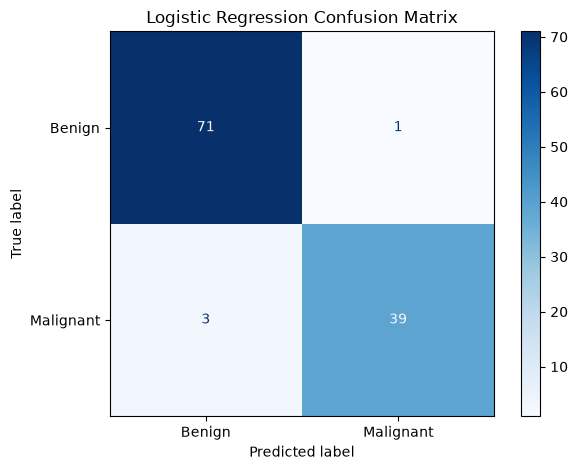

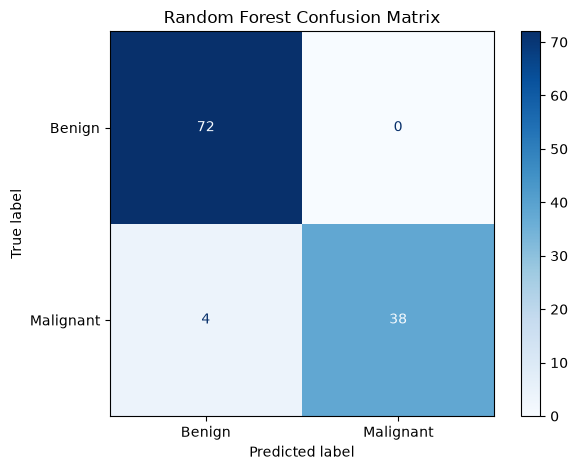

Logistic Regression ROC-AUC: 0.9960
Random Forest ROC-AUC: 0.9942


In [ ]:
# ==========================================
# STEP 5: MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import matplotlib.pyplot as plt
import pandas as pd

# Store models and predictions
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": forest_model
}

predictions = {
    "Logistic Regression": logistic_predictions,
    "Random Forest": forest_predictions
}

# ==========================================
# 1. CLASSIFICATION REPORTS
# ==========================================

for name, y_pred in predictions.items():

    print(f"\n{name}")
    print("=" * 40)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Benign", "Malignant"],
            digits=3
        )
    )

# ==========================================
# 2. CONFUSION MATRICES
# ==========================================

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. ROC-AUC SCORES
# ==========================================

for name, model in models.items():

    # Probability of malignant classification
    y_prob = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)

    print(f"{name} ROC-AUC: {auc:.4f}")

## Model Evaluation Results

Both Logistic Regression and Random Forest achieved 96.49% accuracy on the testing dataset.

However, the confusion matrices showed differences in their predictions. Logistic Regression correctly identified 39 of the 42 malignant cases and missed 3. Random Forest correctly identified 38 malignant cases and missed 4.

Logistic Regression had a malignant recall of 92.9%, compared with 90.5% for Random Forest. This is important because missing a malignant tumor could have serious consequences.

The ROC-AUC scores were also slightly different. Logistic Regression achieved 0.9960, while Random Forest achieved 0.9942.

Based on these results, Logistic Regression performed slightly better at identifying malignant cases in this test set. However, both models performed well, and further testing would be needed before drawing broader conclusions.

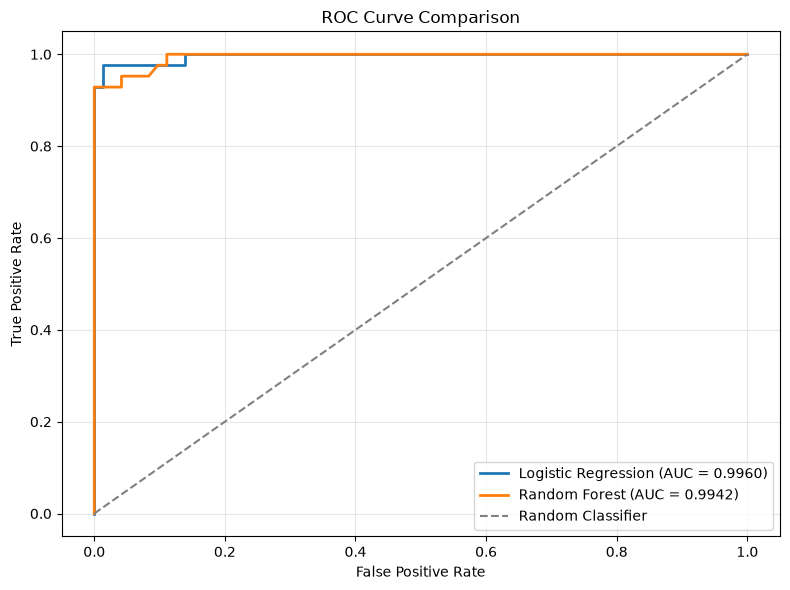

ROC comparison plot saved successfully!


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate predicted probabilities for malignant tumors
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
forest_prob = forest_model.predict_proba(X_test)[:, 1]

# Calculate ROC curve coordinates
fpr_log, tpr_log, _ = roc_curve(y_test, logistic_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, forest_prob)

# Calculate area under each ROC curve
auc_log = roc_auc_score(y_test, logistic_prob)
auc_rf = roc_auc_score(y_test, forest_prob)

# Plot both models
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {auc_log:.4f})",
    linewidth=2
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})",
    linewidth=2
)

# Reference line for random classification
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("roc_curve_comparison.png", dpi=300)
plt.show()

print("ROC comparison plot saved successfully!")

## ROC Curve Interpretation

The ROC curves show how well Logistic Regression and Random Forest distinguish between benign and malignant tumors at different classification thresholds.

Logistic Regression achieved an ROC-AUC of 0.9960, while Random Forest achieved 0.9942. Both curves were close to the top-left corner, showing strong classification performance on the testing dataset.

Logistic Regression had a slightly higher ROC-AUC, but the difference was small. Both models performed well, and additional testing would be needed to determine whether one consistently performs better.

Top 10 Random Forest Features:


worst perimeter         0.1479
worst area              0.1323
worst concave points    0.1101
mean concave points     0.0882
worst radius            0.0851
mean radius             0.0606
mean perimeter          0.0605
mean area               0.0447
mean concavity          0.0441
worst concavity         0.0328
dtype: float64


Top 10 Logistic Regression Features:


worst texture          1.4341
radius error           1.2333
worst symmetry         1.0613
mean concave points    0.9528
worst concavity        0.9114
area error             0.9090
compactness error      0.9069
worst area             0.9005
worst radius           0.8970
mean concavity         0.7823
dtype: float64

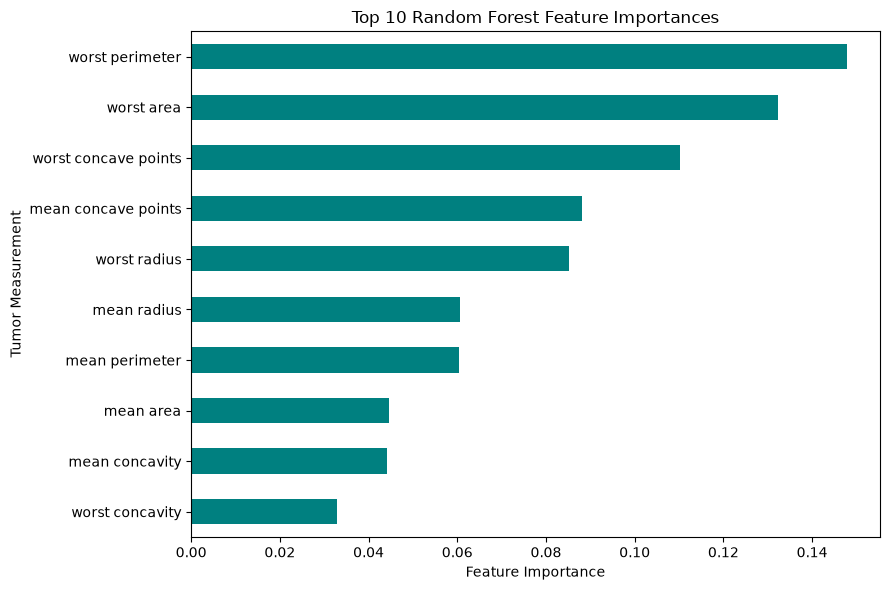

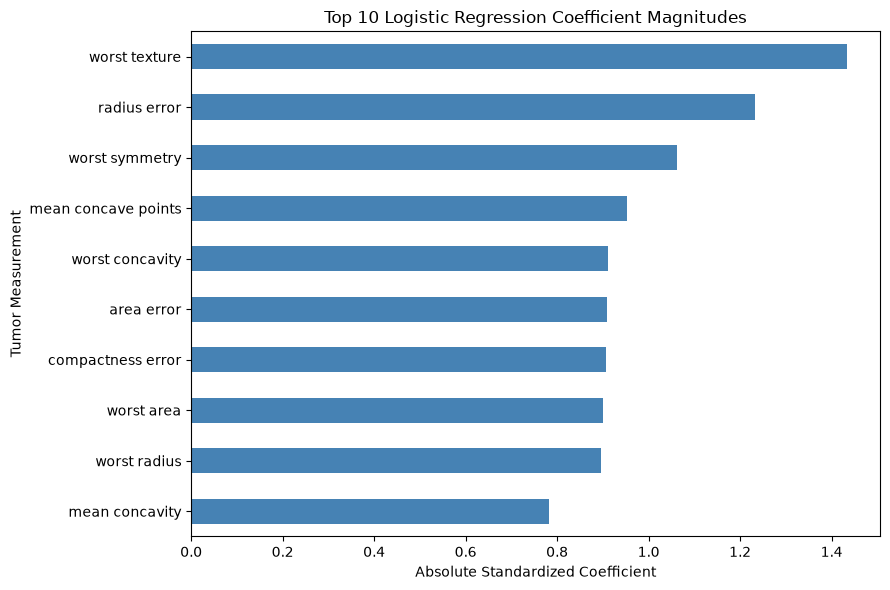

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# STEP 7: FEATURE IMPORTANCE
# ==========================================

# Random Forest feature importance
rf_importance = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Logistic Regression coefficients
lr_coefficients = pd.Series(
    logistic_model.named_steps["classifier"].coef_[0],
    index=X_train.columns
)

# Show the top 10 features for Random Forest
print("Top 10 Random Forest Features:")
display(rf_importance.head(10).round(4))

# Show the top 10 Logistic Regression features
# Absolute coefficient size shows strength, not direction
print("\nTop 10 Logistic Regression Features:")
display(
    lr_coefficients.abs()
    .sort_values(ascending=False)
    .head(10)
    .round(4)
)

# Plot Random Forest feature importance
plt.figure(figsize=(9, 6))

rf_importance.head(10).sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Tumor Measurement")
plt.tight_layout()
plt.savefig("random_forest_feature_importance.png", dpi=300)
plt.show()

# Plot Logistic Regression coefficient magnitudes
plt.figure(figsize=(9, 6))

lr_coefficients.abs().sort_values(
    ascending=False
).head(10).sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Logistic Regression Coefficient Magnitudes")
plt.xlabel("Absolute Standardized Coefficient")
plt.ylabel("Tumor Measurement")
plt.tight_layout()
plt.savefig("logistic_regression_coefficients.png", dpi=300)
plt.show()

## Feature Importance Results

I examined the most important features used by Logistic Regression and Random Forest to understand which measurements influenced their predictions.

For Random Forest, the most important features were worst perimeter (0.1479), worst area (0.1323), and worst concave points (0.1101). These measurements describe characteristics of tumor size and shape.

For Logistic Regression, the largest absolute coefficients were worst texture (1.4341), radius error (1.2333), and worst symmetry (1.0613).

The two models ranked features differently because they use different methods to make predictions. These rankings help explain the models, but they do not prove that the measurements cause cancer.

Overall, both models used information about tumor characteristics to distinguish benign and malignant samples.